# Local microenvironment variation around Aβ plaques (MERFISH)

The colorectal tutorial (`global_spatial_variation_tutorial.ipynb`) evaluates SAFFRON against a **global** 1-D gradient. This one instead evaluates against **local** microenvironment measures around amyloid-β plaques in an Alzheimer's disease MERFISH brain dataset.

## Using your own data

SAFFRON only needs one or more embeddings/SAE features in `.obsm` and a local measure in `.obs`. Replace the cells below with your own data, update `REPRESENTATIONS` to your own keys, and swap or omit `adata.uns["landmark_points"]` — a demo-specific marker array, not a SAFFRON requirement.

`data/merfish_plaque.h5ad` bundles one full tissue section (27,741 cells, ~196 plaques): three precomputed SAE feature sets (`gene_sae_features`, `geneformer_sae_features`, `spatialfusion_rna_sae_features`), plaque centroid coordinates for the whole section in `adata.uns["landmark_points"]` (and for the patch below in `adata.uns["patch_landmark_points"]`), `adata.X` — the log-normalized 300-gene MERFISH panel these SAE features were trained on — and `adata.layers["counts"]`, the same panel's raw counts, for anyone benchmarking their own embeddings against the same input.

For a fast, self-contained walkthrough this notebook works on a 350 µm patch (636 cells, 6 plaques) of that section, flagged by `adata.obs["in_patch"]` — SAFFRON has no notion of "patches" itself, so use the full section directly if you don't need one. Three local measures (`τ`), computed for every cell in the section:
- `dam_score` — mean expression of the Keren-Shaul disease-associated-microglia (DAM) gene panel
- `micro_density` — microglia within 100 µm, as a density (cells / mm²)
- `distance_to_plaque` — negative distance to the nearest plaque (higher = closer)

In [1]:
import warnings
import anndata
import numpy as np

from saffron import SAFFRON
from saffron.utils import plot_spatial_scatter

# OMP stops early when some SAE features are linearly dependent; this is harmless, so hide the warning
warnings.filterwarnings("ignore", message="Orthogonal matching pursuit ended prematurely")

In [2]:
adata_full = anndata.read_h5ad("data/merfish_plaque.h5ad")  # or anndata.read_h5ad("your_data.h5ad")
adata = adata_full[adata_full.obs["in_patch"]].copy()  # this demo's 350 um patch; skip this line to use the whole section
adata.uns["landmark_points"] = adata_full.uns["patch_landmark_points"]  # the 6 plaques found within the patch itself
adata

AnnData object with n_obs × n_vars = 636 × 300
    obs: 'dam_score', 'micro_density', 'plaque_distance', 'is_micro', 'cluster_coarse', 'distance_to_plaque', 'in_patch'
    uns: 'landmark_points', 'patch_landmark_points', 'patch_radius_um'
    obsm: 'gene_sae_features', 'geneformer_sae_features', 'spatial', 'spatialfusion_rna_sae_features'
    layers: 'counts'

## Step 1: Evaluate Gene SAE vs. a representative SFM SAE, for each measure

For each measure, fit (loads instantly — the SAE features are already cached in `adata.obsm`) and evaluate both the Gene SAE and one foundation model's SAE against it, over the 636 cells in the patch — the same comparison as Fig. 4b of the paper (Geneformer for the DAM score, SpatialFusion (RNA) for microglial density and distance to plaque).

In [3]:
# tau_key -> [(features_key, label), ...]: replace with your own .obs measures and .obsm keys
REPRESENTATIONS = {
    "dam_score":          [("gene_sae_features", "Gene SAE"), ("geneformer_sae_features", "Geneformer SAE")],
    "micro_density":      [("gene_sae_features", "Gene SAE"), ("spatialfusion_rna_sae_features", "SF (RNA) SAE")],
    "distance_to_plaque": [("gene_sae_features", "Gene SAE"), ("spatialfusion_rna_sae_features", "SF (RNA) SAE")],
}

results = {}
for tau_key, reps in REPRESENTATIONS.items():
    for rep_key, rep_label in reps:
        model = SAFFRON().fit(adata, features_key=rep_key)
        result = model.evaluate(adata, tau_key=tau_key, features_key=rep_key, restrict_support=False)
        results[(tau_key, rep_key)] = result
        print(f"{tau_key:18s} {rep_label:16s} best=#{result.correlation.best_feature:4d} rho={result.correlation.best_rho:+.3f}")

dam_score          Gene SAE         best=# 460 rho=+0.553


dam_score          Geneformer SAE   best=# 143 rho=-0.586
micro_density      Gene SAE         best=#  54 rho=+0.193


micro_density      SF (RNA) SAE     best=#   6 rho=+0.331


distance_to_plaque Gene SAE         best=# 288 rho=+0.216


distance_to_plaque SF (RNA) SAE     best=#  10 rho=-0.383


## Step 2: Visualize each measure and its best SAE features in the tissue

Each plaque-associated measure across the patch, next to the SAE feature most correlated with it for each representation (as in Fig. 4b of the paper). Red crosses mark `adata.uns["landmark_points"]`, i.e. the plaque centroids in this demo.

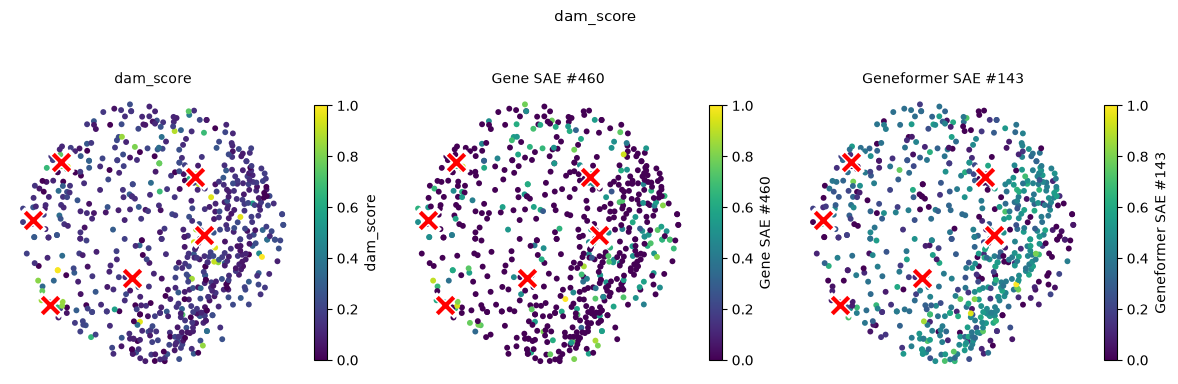

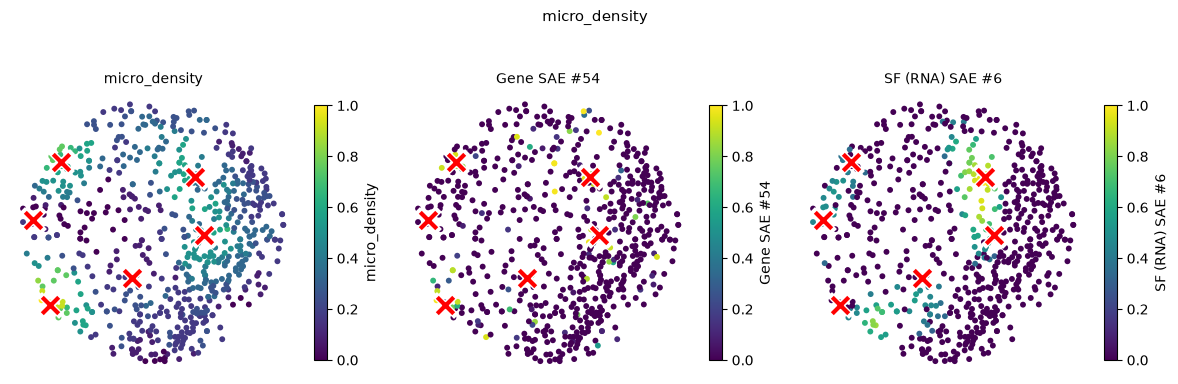

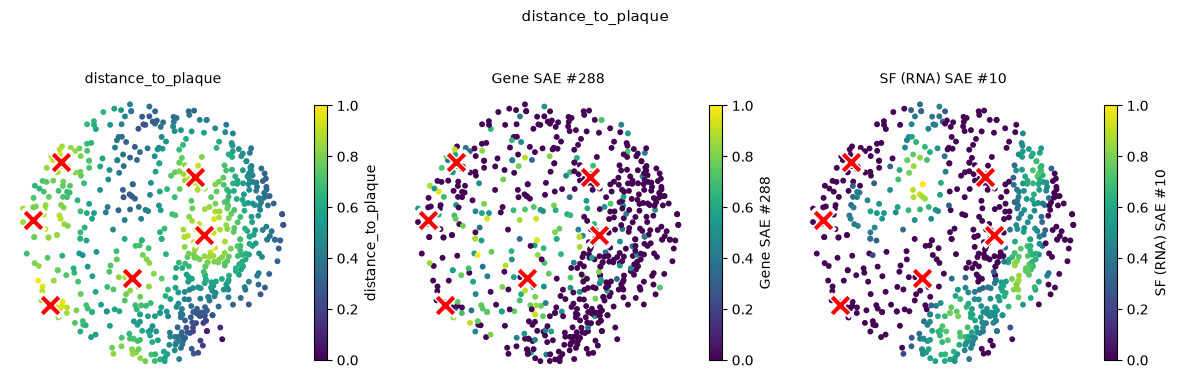

In [4]:
for tau_key, reps in REPRESENTATIONS.items():
    panels = {tau_key: adata.obs[tau_key].values}
    for rep_key, rep_label in reps:
        feat = results[(tau_key, rep_key)].correlation.best_feature
        panels[f"{rep_label} #{feat}"] = adata.obsm[rep_key][:, feat]
    plot_spatial_scatter(adata, panels, markers=adata.uns["landmark_points"], suptitle=tau_key)